# QAOA and quantum machine learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/08_Qiskit_QAOA_QML.ipynb)

Content (textbook, chapters 9 and 10):
* Recap: the variational loop
* From a binary problem to an Ising Hamiltonian
* QAOA for MaxCut
  * one edge, layer by layer
  * a triangle and a ring
  * from the expectation value to a solution
* Quantum machine learning
  * encoding classical data into qubits
  * a one-qubit variational classifier and data re-uploading
  * quantum kernels and a kernel SVM
  * kernel concentration: when the kernel becomes useless

Sections 2 and 3 are the same as in 07, for those who did not get there. Every section starts with a short summary of the theory,
so the notebook can be followed without the lecture.

**How to use this notebook.** As in 05 to 07: a cell after **Your turn** says what we want and leaves the rest to you, with a collapsed
solution below it. Nothing later depends on your cell. The figures are drawn by helper functions from the collapsed cell in section 0;
every figure is a single line such as `show_svm(...)`.

## 0. Setup

In Colab uncomment and run the first cell after every runtime restart. Then run the two cells below it, the second one holds the plotting
helpers and is collapsed.

In [1]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib scipy

In [2]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator

print(qiskit.__version__)

shots = 1000
sim = AerSimulator()


def run(qc: QuantumCircuit, shots: int = shots) -> dict:
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

2.1.2


In [3]:
#@title Plotting helpers (run it, no need to read it)
from matplotlib.patches import Patch


def _clean(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)


def _pi_label(x: float) -> str:
    f = Fraction(x / np.pi).limit_denominator(16)
    if abs(float(f) * np.pi - x) > 1e-6:
        return f'{x:.3f}'
    if f == 0:
        return '0'
    num = '' if f.numerator == 1 else str(f.numerator)
    return rf'${num}\pi$' if f.denominator == 1 else rf'${num}\pi/{f.denominator}$'


def _pi_axis(ax, top: float, step: float, axis: str = 'x'):
    ticks = np.arange(0, top + 1e-9, step)
    (ax.set_xticks if axis == 'x' else ax.set_yticks)(ticks, [_pi_label(t) for t in ticks])


def show_penalty(g, Ps):
    strings = ['00', '01', '10', '11']
    fig, axes = plt.subplots(1, len(Ps), figsize=(3.3 * len(Ps), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, P in zip(axes, Ps):
        vals = np.array([g(int(s[0]), int(s[1])) + P * (int(s[0]) + int(s[1]) - 1)**2 for s in strings])
        feasible = np.array([s in ('01', '10') for s in strings])
        ax.bar(strings, vals, color=np.where(feasible, 'tab:green', 'tab:gray'))
        minima = np.isclose(vals, vals.min())
        for i in np.flatnonzero(minima):
            ax.text(i, vals[i], 'min', ha='center', va='top' if vals[i] < 0 else 'bottom', fontweight='bold')
        if feasible[minima].all():
            status = 'constraint holds'
        elif feasible[minima].any():
            status = 'tie'
        else:
            status = 'constraint broken'
        ax.set_title(f'P = {P}: {status}')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xlabel('$x_1x_2$')
        _clean(ax)
    axes[0].set_ylabel('$f_P(x_1, x_2)$')
    axes[0].legend(handles=[Patch(color='tab:green', label='$x_1+x_2=1$'), Patch(color='tab:gray', label='violates it')],
                    fontsize=8, loc='upper right')
    plt.tight_layout()
    plt.show()


def _wheels(ax, amps, labels, scale):
    # One wheel per amplitude: disc size = modulus, hand and colour = phase
    for c, a in enumerate(amps):
        a = a / scale * 0.42
        phase = np.angle(a) % (2 * np.pi)
        ax.add_patch(plt.Circle((c, 0), 0.42, fill=False, color='0.8', linewidth=1))
        if abs(a) > 1e-6:
            ax.add_patch(plt.Circle((c, 0), abs(a), color=plt.cm.twilight(phase / (2 * np.pi))))
            hand = 'white' if np.pi / 2 < phase < 3 * np.pi / 2 else 'black'
            ax.plot([c, c + a.real], [0, a.imag], color=hand, linewidth=1.5, solid_capstyle='round')
    ax.set_xlim(-0.55, len(amps) - 0.45)
    ax.set_ylim(-0.55, 0.55)
    ax.set_aspect('equal')
    ax.set_xticks(range(len(amps)), labels)
    ax.set_yticks([])
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)


def show_qaoa_stages(gamma: float, beta: float):
    qc = QuantumCircuit(2)
    qc.h([0, 1])
    stages = [('after $H$', Statevector(qc))]
    qc.rzz(-gamma, 0, 1)
    stages.append((r'after cost layer $e^{-i\gamma H_C}$', Statevector(qc)))
    qc.rx(2 * beta, [0, 1])
    stages.append((r'after mixer $e^{-i\beta H_M}$', Statevector(qc)))
    labels = ['00', '01', '10', '11']
    colors = ['tab:gray', 'tab:green', 'tab:green', 'tab:gray']
    fig, axes = plt.subplots(3, 2, figsize=(9, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
    for r, (name, sv) in enumerate(stages):
        amps = sv.data
        ref = amps[np.flatnonzero(np.abs(amps) > 1e-6)[0]]
        _wheels(axes[r, 0], amps * np.exp(-1j * np.angle(ref)), labels, scale=1 / np.sqrt(2))
        axes[r, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=10)
        probs = np.abs(amps)**2
        axes[r, 1].bar(labels, probs, color=colors)
        for i, p in enumerate(probs):
            axes[r, 1].text(i, p + 0.02, f'{p:.2f}', ha='center', fontsize=9)
        axes[r, 1].set_ylim(0, 1.1)
        _clean(axes[r, 1])
    axes[0, 0].set_title('amplitudes (size = modulus, hand = phase)', fontsize=10)
    axes[0, 1].set_title('probabilities (green = edge cut)', fontsize=10)
    fig.suptitle(f'one edge, $\\gamma$ = {_pi_label(gamma)}, $\\beta$ = {_pi_label(beta)}')
    plt.tight_layout()
    plt.show()


def show_heatmap(gammas, betas, F, marks=(), title=''):
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(F, origin='lower', aspect='auto', cmap='viridis',
                   extent=[gammas[0], gammas[-1], betas[0], betas[-1]])
    plt.colorbar(im, ax=ax, label=r'expected cut $F_1(\gamma,\beta)$')
    b, g = np.unravel_index(F.argmax(), F.shape)
    ax.plot(gammas[g], betas[b], '*', color='white', ms=14, label=f'grid maximum {F.max():.3f}')
    for k, (gm, bm) in enumerate(marks):
        ax.plot(gm, bm, 'o', mfc='none', mec='tab:red', ms=16, mew=2, label='your points' if k == 0 else None)
    _pi_axis(ax, 2 * np.pi, np.pi / 2, 'x')
    _pi_axis(ax, np.pi / 2, np.pi / 8, 'y')
    ax.set_xlabel(r'$\gamma$ (cost)')
    ax.set_ylabel(r'$\beta$ (mixer)')
    ax.set_title(title)
    ax.legend(loc='upper right', fontsize=8, framealpha=0.8)
    plt.show()


def _draw_cut(ax, edges, bits):
    n = len(bits)
    x = bits[::-1]                       # x[i] is the bit of qubit i
    pos = [(np.sin(2 * np.pi * i / n), np.cos(2 * np.pi * i / n)) for i in range(n)]
    for i, j in edges:
        cut = x[i] != x[j]
        ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]], color='tab:red' if cut else '0.6',
                lw=3 if cut else 1.5, ls='-' if cut else '--', zorder=1)
    for i, (px, py) in enumerate(pos):
        ax.scatter(px, py, s=520, color='tab:orange' if x[i] == '1' else 'tab:blue', edgecolor='k', zorder=2)
        ax.text(px, py, str(i), color='white', ha='center', va='center', fontweight='bold', zorder=3)
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f'{bits}: cut = {cut_value(bits, edges)}', fontsize=10)


def show_samples(edges, samples: dict):
    n = len(next(iter(next(iter(samples.values())))))
    cuts = {format(k, f'0{n}b'): cut_value(format(k, f'0{n}b'), edges) for k in range(2**n)}
    c_max = max(cuts.values())
    order = sorted(cuts, key=lambda s: (-cuts[s], s))
    fig, axes = plt.subplots(len(samples), 2, figsize=(12, 3 * len(samples)),
                             gridspec_kw={'width_ratios': [1, 4]}, squeeze=False)
    for row, (name, counts) in enumerate(samples.items()):
        total = sum(counts.values())
        probs = np.array([counts.get(s, 0) / total for s in order])
        mean = sum(counts[s] * cuts[s] for s in counts) / total
        p_opt = sum(counts[s] for s in counts if cuts[s] == c_max) / total
        top = max(counts, key=lambda s: (cuts[s], counts[s]))
        _draw_cut(axes[row, 0], edges, top)
        ax = axes[row, 1]
        ax.bar(range(len(order)), probs, color=[plt.cm.viridis(cuts[s] / c_max) for s in order])
        ax.axhline(1 / 2**n, color='0.3', ls=':', lw=1.2, label='random guess')
        for value in sorted(set(cuts.values()), reverse=True):
            idx = [i for i, s in enumerate(order) if cuts[s] == value]
            ax.axvline(idx[-1] + 0.5, color='0.85', lw=1)
            ax.text(np.mean(idx), 1.02, f'cut {value}', transform=ax.get_xaxis_transform(), ha='center', fontsize=9)
        ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8 if n > 4 else 9)
        ax.set_xlim(-0.6, len(order) - 0.4)
        ax.set_ylabel('frequency')
        ax.set_title(f'{name}:  mean cut {mean:.2f} of {c_max},  P(optimum) = {p_opt:.2f}', pad=18)
        ax.legend(fontsize=8, loc='upper right')
        _clean(ax)
    plt.tight_layout()
    plt.show()


def show_success(qs, N_max=80):
    N = np.arange(1, N_max + 1)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for q in qs:
        ax.plot(N, 1 - (1 - q)**N, label=f'q = {q}')
    for target in (0.95, 0.99):
        ax.axhline(target, color='0.5', ls=':', lw=1)
        ax.text(N_max, target, f' {target:.0%}', va='center', fontsize=9)
    ax.set_xlabel('number of final samples $N$')
    ax.set_ylabel('P(at least one optimum)')
    ax.legend(loc='lower right')
    _clean(ax)
    plt.show()



# ---------- quantum machine learning ----------
_CLS = {1: 'tab:blue', -1: 'tab:orange'}


def _bloch(qc: QuantumCircuit):
    psi = Statevector(qc)
    return [psi.expectation_value(SparsePauliOp(p)).real for p in 'XYZ']


def _circle(ax, h_names, v_names, title):
    t = np.linspace(0, 2 * np.pi, 200)
    ax.plot(np.cos(t), np.sin(t), color='0.8', lw=1)
    ax.axhline(0, color='0.92', lw=0.8, zorder=0)
    ax.axvline(0, color='0.92', lw=0.8, zorder=0)
    for (px, py, name) in [(1.22, 0, h_names[0]), (-1.22, 0, h_names[1]), (0, 1.15, v_names[0]), (0, -1.15, v_names[1])]:
        ax.text(px, py, name, ha='center', va='center', fontsize=11)
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.35, 1.35)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=10)


def show_encodings(xs):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    specs = [(r'angle: $R_Y(x)|0\rangle$ (xz plane)', lambda qc, x: qc.ry(x, 0), (0, 2),
              (r'$|+\rangle$', r'$|-\rangle$'), (r'$|0\rangle$', r'$|1\rangle$')),
             (r'phase: $P(x)|+\rangle$ (equator, xy plane)', lambda qc, x: (qc.h(0), qc.p(x, 0)), (0, 1),
              (r'$|+\rangle$', r'$|-\rangle$'), (r'$|{+i}\rangle$', r'$|{-i}\rangle$')),
             (r'$R_Z(x)|0\rangle$ (xz plane)', lambda qc, x: qc.rz(x, 0), (0, 2),
              (r'$|+\rangle$', r'$|-\rangle$'), (r'$|0\rangle$', r'$|1\rangle$'))]
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(xs)))
    for ax, (title, gate, (h, v), hn, vn) in zip(axes, specs):
        _circle(ax, hn, vn, title)
        for k, (x, c) in enumerate(zip(xs, colors)):
            qc = QuantumCircuit(1)
            gate(qc, x)
            r = _bloch(qc)
            tip = np.array([r[h], r[v]])
            ax.annotate('', xy=tip, xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=c, lw=1.8))
            if ax is axes[2]:
                continue
            side = np.array([tip[1], -tip[0]])             # perpendicular to the arrow
            pos = 0.62 * tip + 0.13 * side
            ax.text(*pos, _pi_label(x), color=c, fontsize=10, ha='center', va='center', fontweight='bold')
    axes[2].text(0.12, 0.55, 'every x:\nstill $|0\\rangle$', color='0.3', fontsize=10, ha='left', va='center')
    plt.tight_layout()
    plt.show()


def _accuracy(model, params, X, y):
    return np.mean(np.sign([model(x, params) for x in X]) == y)


def show_fits(model, fits: dict, X, y):
    xs = np.linspace(0, 2 * np.pi, 300)
    fig, axes = plt.subplots(1, len(fits), figsize=(4.6 * len(fits), 3.6), squeeze=False)
    for ax, (name, params) in zip(axes[0], fits.items()):
        f = np.array([model(x, params) for x in xs])
        ax.fill_between(xs, -1.1, 1.1, where=f >= 0, color=_CLS[1], alpha=0.12, lw=0)
        ax.fill_between(xs, -1.1, 1.1, where=f < 0, color=_CLS[-1], alpha=0.12, lw=0)
        ax.plot(xs, f, color='0.25', lw=1.8, label=r'$f_\theta(x)$')
        for cls in (1, -1):
            sel = y == cls
            ax.plot(X[sel], y[sel], 'o', color=_CLS[cls], ms=7, mec='k', label=f'class {cls:+d}')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_ylim(-1.15, 1.15)
        _pi_axis(ax, 2 * np.pi, np.pi / 2)
        ax.set_xlabel('$x$')
        acc = _accuracy(model, params, X, y)
        loss = np.mean([(model(x, params) - t)**2 for x, t in zip(X, y)])
        ax.set_title(f'{name}\nloss {loss:.3f}, accuracy {acc:.0%}', fontsize=10)
        _clean(ax)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout()
    plt.show()


def show_loss(thetas, losses):
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(thetas, losses, color='tab:purple')
    i = int(np.argmin(losses))
    ax.plot(thetas[i], losses[i], '*', color='tab:red', ms=14, label=rf'minimum at $\theta$ = {thetas[i]:.3f}')
    _pi_axis(ax, 2 * np.pi, np.pi / 3)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'loss $\mathcal{L}(\theta)$')
    ax.legend()
    _clean(ax)
    plt.show()


def show_gram(K, y, title='Gram matrix'):
    order = np.argsort(-y, kind='stable')
    fig, ax = plt.subplots(figsize=(4.6, 4))
    im = ax.imshow(K[np.ix_(order, order)], cmap='magma', vmin=0, vmax=1)
    n_plus = int((y == 1).sum())
    ax.axhline(n_plus - 0.5, color='w', lw=1)
    ax.axvline(n_plus - 0.5, color='w', lw=1)
    ax.set_title(title + '\n(sorted: class +1 first)', fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(im, ax=ax, label='$k(x_i, x_j)$')
    plt.show()


def show_svm(kernels: dict, Xtr, ytr, Xte, yte, C=10.0):
    g = np.linspace(0, np.pi, 41)
    G1, G2 = np.meshgrid(g, g)
    grid = np.c_[G1.ravel(), G2.ravel()]
    fig, axes = plt.subplots(1, len(kernels), figsize=(3.6 * len(kernels), 3.9), squeeze=False)
    for ax, (name, k) in zip(axes[0], kernels.items()):
        alpha, b = svm_fit(k(Xtr, Xtr), ytr, C)
        acc_tr = np.mean(np.sign(svm_predict(k(Xtr, Xtr), ytr, alpha, b)) == ytr)
        acc_te = np.mean(np.sign(svm_predict(k(Xtr, Xte), ytr, alpha, b)) == yte)
        F = svm_predict(k(Xtr, grid), ytr, alpha, b).reshape(G1.shape)
        ax.contourf(G1, G2, F, levels=[-1e9, 0, 1e9], colors=[_CLS[-1], _CLS[1]], alpha=0.18)
        ax.contour(G1, G2, F, levels=[0], colors='0.3', linewidths=1)
        for cls in (1, -1):
            sel = ytr == cls
            ax.scatter(Xtr[sel, 0], Xtr[sel, 1], color=_CLS[cls], edgecolor='k', s=40, zorder=3)
        sv = alpha > 1e-6
        ax.scatter(Xtr[sv, 0], Xtr[sv, 1], s=140, facecolor='none', edgecolor='0.2', lw=1, zorder=2)
        ax.set_title(f'{name}\ntrain {acc_tr:.0%}, test {acc_te:.0%}, {sv.sum()} SV', fontsize=10)
        _pi_axis(ax, np.pi, np.pi / 2, 'x')
        _pi_axis(ax, np.pi, np.pi / 2, 'y')
        ax.set_aspect('equal')
        ax.set_xlabel('$x_1$')
    axes[0, 0].set_ylabel('$x_2$')
    plt.tight_layout()
    plt.show()


def show_concentration(ns, mean_k, shots, grams: dict):
    fig = plt.figure(figsize=(13, 3.8))
    ax = fig.add_subplot(1, len(grams) + 2, (1, 2))
    ax.semilogy(ns, mean_k, 'o', color='tab:purple', label=r'mean off-diagonal $k$')
    ax.semilogy(ns, (0.5 + 2 / np.pi**2)**np.array(ns), '--', color='tab:purple', lw=1, label=r'$(1/2 + 2/\pi^2)^n \approx 0.70^n$')
    ax.axhline(1 / shots, color='tab:red', ls=':', label=f'1/N for N = {shots} shots')
    ax.set_xlabel('number of qubits $n$')
    ax.set_ylabel('kernel value')
    ax.set_xticks(ns[::2])
    ax.legend(fontsize=8)
    _clean(ax)
    for i, (n, K) in enumerate(grams.items()):
        a = fig.add_subplot(1, len(grams) + 2, i + 3)
        a.imshow(K, cmap='magma', vmin=0, vmax=1)
        a.set_title(f'Gram matrix, n = {n}', fontsize=10)
        a.set_xticks([])
        a.set_yticks([])
    plt.tight_layout()
    plt.show()

## 1. Recap: the variational loop

Variational algorithms split the work between a small quantum circuit and a classical computer (textbook 9.1, notebook 07).

* An **ansatz** $U(\boldsymbol\theta)$, a short circuit with tunable angles, prepares $|\psi(\boldsymbol\theta)\rangle = U(\boldsymbol\theta)|0\rangle$.
* The quantum computer **estimates** a cost, usually an expectation value $C(\boldsymbol\theta) = \langle\psi(\boldsymbol\theta)|H|\psi(\boldsymbol\theta)\rangle$.
  $H$ is written as a sum of Pauli strings $H = \sum_k c_k P_k$, and each $\langle P_k\rangle$ comes from repeated measurements: rotate
  into the eigenbasis of $P_k$ ($\mathsf H$ for $X$, $S^\dagger\mathsf H$ for $Y$), measure, count the outcomes as $\pm 1$ and average.
* A **classical optimiser** proposes new angles, and the loop repeats:

$$\boldsymbol\theta \;\longrightarrow\; \boxed{\text{QPU: prepare and measure, many shots}} \;\xrightarrow{\text{counts}}\;
\boxed{\text{CPU: estimate } C(\boldsymbol\theta),\ \text{propose new } \boldsymbol\theta} \;\longrightarrow\; \boldsymbol\theta' \;\longrightarrow \cdots$$

**Variational principle.** For any state, $\langle\psi|H|\psi\rangle = \sum_k |a_k|^2 E_k \ge E_0$: the energy is an average of the eigenvalues
and never goes below the lowest one. VQE (*variational quantum eigensolver*) pushes this upper bound down.

**What it costs and what can go wrong.**
* The estimate has shot noise $\sigma \sim 1/\sqrt N$. In 07 the one-parameter VQE needed about 30 evaluations $\times$ 2 settings
  $\times$ 1000 shots $\approx$ 60 000 state preparations.
* The ansatz must be able to reach a good state (ansatz error), and the landscape must not be flat (**barren plateaus**: for deep or
  global costs the gradients shrink exponentially with the number of qubits).

Today we use the same loop twice: in **QAOA** the cost is a combinatorial problem written as a diagonal Hamiltonian, and in a
**variational classifier** it is a loss function on training data.

## 2. From a binary problem to an Ising Hamiltonian

### 2.1 QUBO $\to$ Ising

Many optimisation problems are a **QUBO** (*quadratic unconstrained binary optimisation*):

$$\min_{x \in \{0,1\}^n} f(x), \qquad f(x) = c + \sum_i a_i x_i + \sum_{i<j} b_{ij} x_i x_j .$$

Substitute $x_i = (1 - z_i)/2$ with $z_i = \pm 1$, and replace $z_i$ by the operator $Z_i$:

$$H_C = c'\,I + \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j .$$

Since $Z_i|x\rangle = (-1)^{x_i}|x\rangle$, we get $H_C|x\rangle = f(x)|x\rangle$: $H_C$ is **diagonal** and its eigenvalues are the values of $f$.
The best bit string is the ground state of $H_C$. It is the same task as in VQE, only the Hamiltonian is diagonal.

**Qubit order in Qiskit.** The last letter of a Pauli label acts on qubit 0: `'IZ'` is $Z$ on qubit 0. We put $x_1$ on qubit 0 and $x_2$ on
qubit 1, so the basis state $|x_2 x_1\rangle$ has index $2x_2 + x_1$.

**Your turn.** Textbook example 9.4.2: $f(x_1, x_2) = 2x_1 - x_2 + 3x_1x_2$.

1. On paper: substitute $x_i = (1 - z_i)/2$ and collect the constant and the coefficients of $z_1$, $z_2$, $z_1z_2$.
2. Write $H_C$ as a `SparsePauliOp` and check that its diagonal is $f$ (textbook table 9.1). Which bit string is the minimum?


In [7]:
def f(x1, x2):
    return 2 * x1 - x2 + 3 * x1 * x2


# H_C = SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ'], [c, h1, h2, J])     # 'IZ' = Z_1 on qubit 0
# diagonal = H_C.to_matrix().diagonal().real
# for x1 in [0, 1]:
#     for x2 in [0, 1]:
#         print(x1, x2, f(x1, x2), diagonal[2 * x2 + x1])



<details>
<summary>Solution</summary>

```python
def f(x1, x2):
    return 2 * x1 - x2 + 3 * x1 * x2


# f = (1 - z1) - (1 - z2)/2 + 3/4 (1 - z1 - z2 + z1 z2) = 5/4 - 7/4 z1 - 1/4 z2 + 3/4 z1 z2
H_C = SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ'], [5 / 4, -7 / 4, -1 / 4, 3 / 4])
diagonal = H_C.to_matrix().diagonal().real
print('x1 x2   f   <x|H_C|x>')
for x1 in [0, 1]:
    for x2 in [0, 1]:
        print(f' {x1}  {x2}  {f(x1, x2):3}  {diagonal[2 * x2 + x1]:6.2f}')
# minimum: x1 x2 = 01, f = -1

```

</details>

The constant $c'I$ does not change which bit string is best, and in $e^{-i\gamma H_C}$ it only gives a global phase, so circuits can drop it.
When we report the value of $f$, we must add it back.

### 2.2 Constraints as penalties (optional)

"Unconstrained" means the constraints have to go into $f$. For $x_1 + x_2 = 1$ we add $P(x_1 + x_2 - 1)^2 = P(1 - x_1 - x_2 + 2x_1x_2)$
(using $x_i^2 = x_i$), which is again quadratic. Textbook example: $g = -x_1 - x_2$. Without the constraint the best choice is $11$.

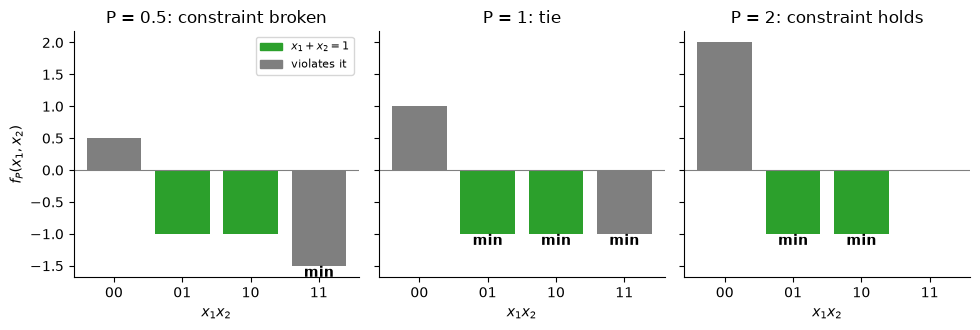

In [ ]:
show_penalty(lambda x1, x2: -x1 - x2, Ps=[0.5, 1, 2])

A small $P$ still lets the forbidden $11$ win, at $P = 1$ there is a tie, and only $P > 1$ forces the constraint. Too large a $P$ is not
free either: it stretches the range of the coefficients and the fine differences of $g$ get lost in the noise.

**Your turn.** Textbook exercise 4: $g = -2x_1 - x_2$. Find the smallest $P$ that enforces $x_1 + x_2 = 1$, first by trying values in
`show_penalty`, then on paper.

In [9]:
# show_penalty(lambda x1, x2: ..., Ps=[...])


<details>
<summary>Solution</summary>

```python
show_penalty(lambda x1, x2: -2 * x1 - x2, Ps=[0.5, 1, 1.5])
# f_P(00) = P, f_P(01) = -1, f_P(10) = -2, f_P(11) = P - 3.
# The feasible minimum is 10 with -2; we need P - 3 > -2, i.e. P > 1. At P = 1 the forbidden 11 ties with 10.
```

</details>

## 3. QAOA for MaxCut

### 3.1 Cost layer and mixer layer

QAOA (*quantum approximate optimisation algorithm*) is a VQE (section 1) with a special ansatz built from the problem itself. Start in
$|s\rangle = |+\rangle^{\otimes n}$ (all bit strings equally likely) and alternate two evolutions:

$$|\boldsymbol\gamma, \boldsymbol\beta\rangle = U_M(\beta_p)\,U_C(\gamma_p)\cdots U_M(\beta_1)\,U_C(\gamma_1)\,|s\rangle,
\qquad U_C(\gamma) = e^{-i\gamma H_C},\quad U_M(\beta) = e^{-i\beta H_M},\quad H_M = \sum_i X_i .$$

$p$ layers, $2p$ parameters. The optimiser tunes them to maximise (or minimise) $F_p = \langle\boldsymbol\gamma,\boldsymbol\beta|H_C|\boldsymbol\gamma,\boldsymbol\beta\rangle$.

**MaxCut.** Split the vertices of a graph into two groups (bit $x_i$ = group) so that as many edges as possible go between the groups.
An edge $(i, j)$ is cut when $x_i \neq x_j$. Since $Z_iZ_j = +1$ for equal and $-1$ for different bits,

$$H_C = \sum_{(i,j)\in E} \frac{I - Z_iZ_j}{2}, \qquad H_C|x\rangle = \text{cut}(x)\,|x\rangle .$$

**As gates.** Qiskit defines $R_{ZZ}(\vartheta) = e^{-i\vartheta Z\otimes Z/2}$, so one edge of the cost layer is
$e^{-i\gamma(I - Z_iZ_j)/2} = e^{-i\gamma/2}R_{ZZ}(-\gamma)$, i.e. `qc.rzz(-gamma, i, j)` up to a global phase. The $X_i$ commute, so the
mixer is $R_X(2\beta)$ on every qubit, `qc.rx(2 * beta, i)`.

**Why both layers?** The cost layer only multiplies each bit string by a phase, $a_x \to a_x e^{-i\gamma\,\text{cut}(x)}$; probabilities do
not change. The mixer mixes bit strings, so these phases can interfere and move probability towards good cuts.

### 3.2 One edge, layer by layer

**Your turn.** Two vertices, one edge, $p = 1$, with $\gamma = \pi/2$, $\beta = \pi/8$ (textbook 9.6).

1. Build the circuit: Hadamard on both qubits, the cost layer `rzz`, the mixer `rx` on both qubits.
2. Print `Statevector(qc).probabilities().round(3)` (order $00, 01, 10, 11$). The textbook says only $01$ and $10$ remain, each with probability $1/2$.
3. Delete the mixer line and print the probabilities again. What do you see?

In [16]:
gamma, beta = np.pi / 2, np.pi / 8

# qc = QuantumCircuit(2)
# qc.h(...)
# qc.rzz(...)              # cost layer
# qc.rx(...)               # mixer
# print(Statevector(qc).probabilities().round(3))      # order 00, 01, 10, 11



<details>
<summary>Solution</summary>

```python
gamma, beta = np.pi / 2, np.pi / 8

qc = QuantumCircuit(2)
qc.h([0, 1])
qc.rzz(-gamma, 0, 1)       # cost layer
qc.rx(2 * beta, [0, 1])    # mixer
print(Statevector(qc).probabilities().round(3))      # order 00, 01, 10, 11: [0, 0.5, 0.5, 0]
print(Statevector(qc))      # order 00, 01, 10, 11: [0, 0.5, 0.5, 0]

# 3. Without the mixer all four probabilities stay 1/4: the cost layer changes phases only.
qc.draw('mpl')
```

</details>

The same as textbook table 9.2 in pictures. Look at the wheels: the cost layer turns the hands of $01$ and $10$ by $-\gamma$ and leaves the sizes
alone. The mixer lets the four amplitudes interfere, and at these angles they cancel exactly on $00$ and $11$. Try $\gamma = \pi/4$ or
$\beta = \pi/16$.

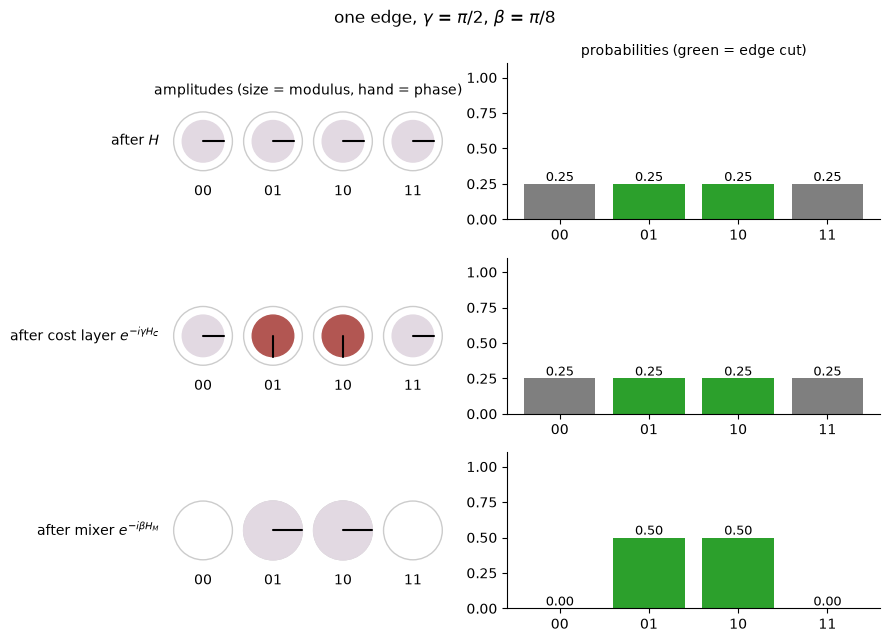

In [17]:
show_qaoa_stages(gamma=np.pi / 2, beta=np.pi / 8)

From now on a general QAOA circuit for any graph, the cut value of a bit string, and the expected cut $F_p$. (Remember: the bit of qubit $i$
is `bits[::-1][i]`.)

F_1 = 0.9999999999999998


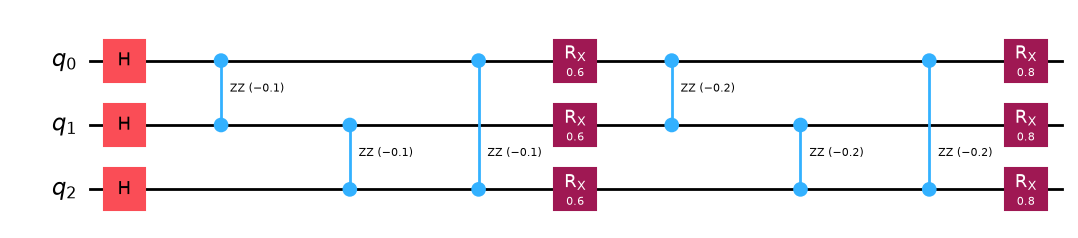

In [18]:
def qaoa(edges, n: int, gammas, betas) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for gamma, beta in zip(gammas, betas):
        for i, j in edges:
            qc.rzz(-gamma, i, j)           # cost layer
        qc.rx(2 * beta, range(n))          # mixer
    return qc


def cut_value(bits: str, edges) -> int:
    x = bits[::-1]
    return sum(x[i] != x[j] for i, j in edges)


def expected_cut(qc: QuantumCircuit, edges) -> float:
    # F_p from the exact state; on hardware we would average cut_value over the samples
    probs = Statevector(qc).probabilities_dict()
    return sum(p * cut_value(bits, edges) for bits, p in probs.items())


edge = [(0, 1)]
print('F_1 =', expected_cut(qaoa(edge, 2, [np.pi / 2], [np.pi / 8]), edge))
qaoa([(0, 1), (1, 2), (0, 2)], 3, [0.1, 0.2], [0.3, 0.4]).draw('mpl')       # a triangle with p = 2

### 3.3 The landscape $F_1(\gamma, \beta)$

For one edge the textbook derives

$$F_1(\gamma, \beta) = \tfrac12\big[1 + \sin(4\beta)\sin\gamma\big]. \qquad (9.53)$$

Here the whole landscape, from the exact state on a $61\times 31$ grid:

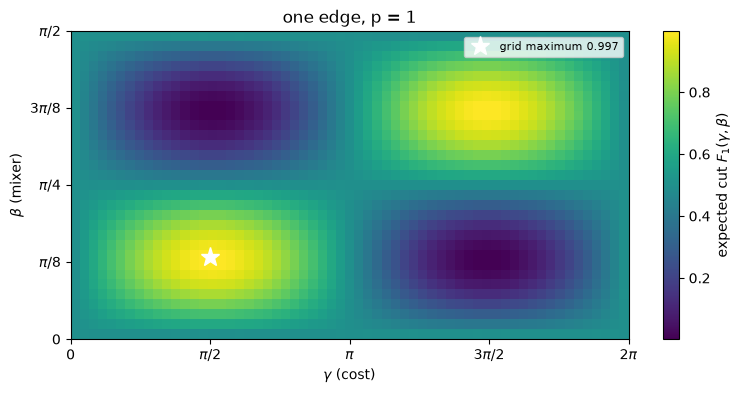

In [20]:
gammas = np.linspace(0, 2 * np.pi, 61)
betas = np.linspace(0, np.pi / 2, 31)
F_edge = np.array([[expected_cut(qaoa(edge, 2, [g], [b]), edge) for g in gammas] for b in betas])
show_heatmap(gammas, betas, F_edge, title='one edge, p = 1')

**Your turn (textbook exercise 5).** From (9.53), find all $(\gamma, \beta) \in [0, 2\pi) \times [0, \pi/2)$ with $F_1 = 1$ and mark them:
`show_heatmap(gammas, betas, F_edge, marks=[(g1, b1), ...])`.

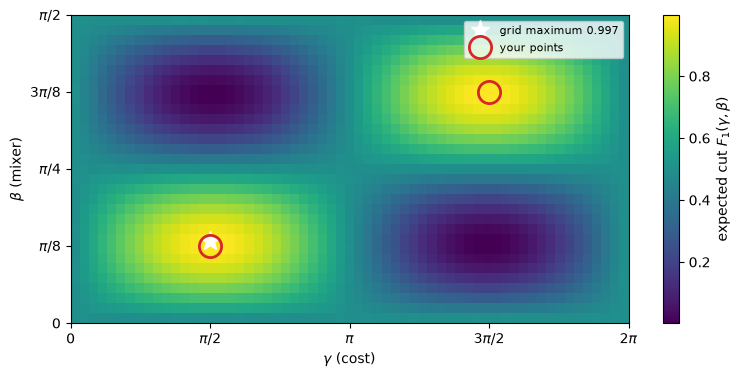

In [21]:
# show_heatmap(gammas, betas, F_edge, marks=[(..., ...), (..., ...)])

show_heatmap(gammas, betas, F_edge, marks=[(np.pi / 2, np.pi / 8), (3 * np.pi / 2, 3 * np.pi / 8)])


<details>
<summary>Solution</summary>

```python
# sin(4 beta) sin(gamma) = 1: either both +1 or both -1
show_heatmap(gammas, betas, F_edge, marks=[(np.pi / 2, np.pi / 8), (3 * np.pi / 2, 3 * np.pi / 8)])
```

</details>

### 3.4 A triangle

Three vertices, three edges. An odd cycle cannot be cut completely: the best cut is 2. **Baseline first:** a random guess gives cut 2 for
6 of the 8 bit strings, so its mean is $1.5$ and $P(\text{optimum}) = 3/4$. QAOA has to beat that.

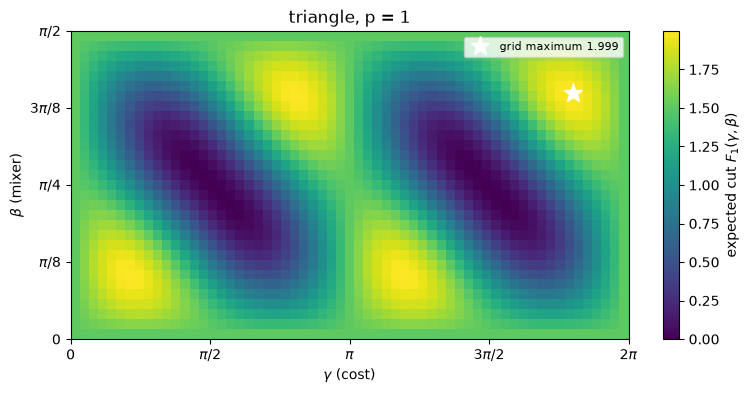

In [23]:
triangle = [(0, 1), (1, 2), (0, 2)]
F_tri = np.array([[expected_cut(qaoa(triangle, 3, [g], [b]), triangle) for g in gammas] for b in betas])
show_heatmap(gammas, betas, F_tri, title='triangle, p = 1')

**Your turn (textbook exercise 6).**

1. Find the exact optimum by brute force: `cut_value` of all 8 bit strings `format(k, '03b')`.
2. Take the best grid point, `b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)`, build `qaoa(...)` with `gammas[g]`, `betas[b]`,
   add `measure_all()` and run it.
3. From the counts compute the mean cut, the best sampled cut and the fraction of optimal samples. Compare with the random guess.

In [ ]:
# for k in range(8):
#     bits = format(k, '03b')
#     print(bits, cut_value(bits, triangle))
# b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
# qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
# ...

<details>
<summary>Solution</summary>

```python
for k in range(8):
    bits = format(k, '03b')
    print(bits, cut_value(bits, triangle))         # 000 and 111 cut 0, all others cut 2

b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
qc.measure_all()
counts = run(qc)

mean = sum(n * cut_value(bits, triangle) for bits, n in counts.items()) / shots
best = max(cut_value(bits, triangle) for bits in counts)
p_opt = sum(n for bits, n in counts.items() if cut_value(bits, triangle) == 2) / shots
print(counts)
print(f'mean cut {mean:.3f} (random 1.5), best sample {best}, P(optimum) = {p_opt:.3f} (random 0.75)')
```

</details>

The same evaluation as a function, and a figure: the bit strings sorted by cut value, the dotted line is a random guess, and on the left the
best sampled cut (blue and orange are the two groups, red edges are cut).

/home/broum/miniconda3/envs/vlq_qaas053/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C_max = 2:  mean cut 2.000 (ratio 1.000),  best sample 2,  P(optimum) = 1.000


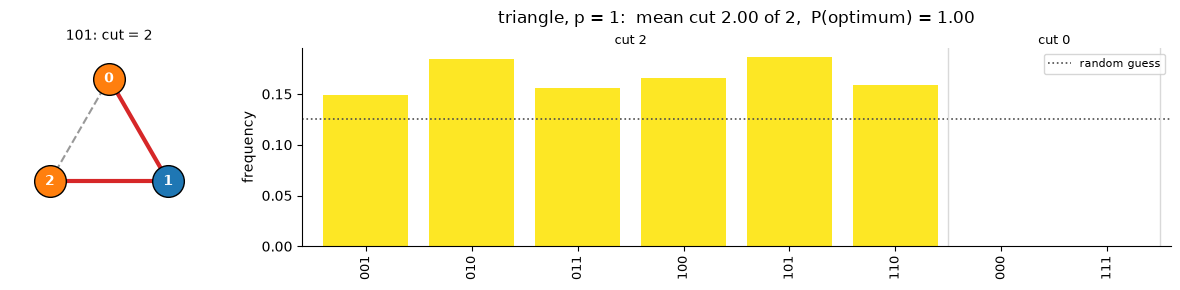

In [24]:
def report(counts: dict, edges) -> None:
    n = len(next(iter(counts)))
    c_max = max(cut_value(format(k, f'0{n}b'), edges) for k in range(2**n))
    total = sum(counts.values())
    mean = sum(m * cut_value(bits, edges) for bits, m in counts.items()) / total
    best = max(cut_value(bits, edges) for bits in counts)
    p_opt = sum(m for bits, m in counts.items() if cut_value(bits, edges) == c_max) / total
    print(f'C_max = {c_max}:  mean cut {mean:.3f} (ratio {mean / c_max:.3f}),  best sample {best},  P(optimum) = {p_opt:.3f}')


b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
qc.measure_all()
counts_tri = run(qc)
report(counts_tri, triangle)
show_samples(triangle, {'triangle, p = 1': counts_tri})

### 3.5 More layers: a ring of four

The square $0-1-2-3-0$ can be cut completely: $0101$ or $1010$, cut 4. With $p = 1$ the best QAOA gets is $F_1 = 3$; each edge "sees" only
its neighbours. With $p = 2$ we have four parameters, a grid is no longer practical, so we let COBYLA search from several random starting
points (*restarts*, textbook 9.7.3). The cost is again the exact $F_p$; on hardware it would be a sampled estimate.

p = 1: F_p = 3.000,  gammas = [2.356],  betas = [2.749]
C_max = 4:  mean cut 2.986 (ratio 0.747),  best sample 4,  P(optimum) = 0.529


p = 2: F_p = 4.000,  gammas = [ 2.237 -1.119],  betas = [1.011 1.119]
C_max = 4:  mean cut 4.000 (ratio 1.000),  best sample 4,  P(optimum) = 1.000


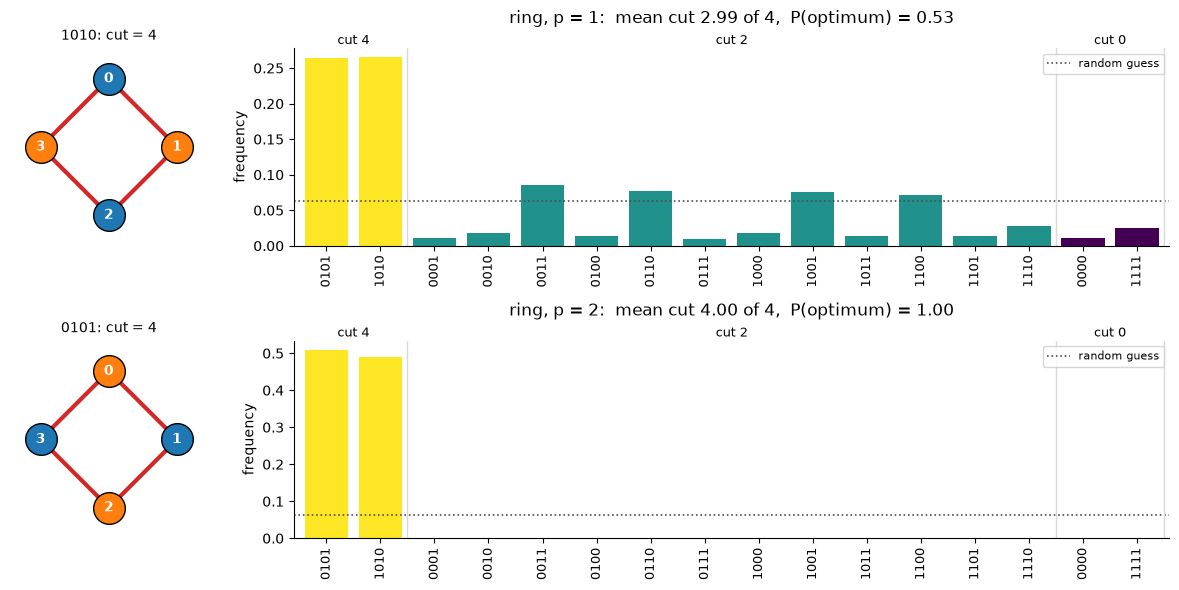

In [ ]:
ring = [(0, 1), (1, 2), (2, 3), (3, 0)]


def best_qaoa(edges, n: int, p: int, starts: int = 5, seed: int = 1):
    # Maximise F_p from several random starting points; returns (F_p, gammas, betas)
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(starts):
        x0 = rng.uniform(0, np.pi, 2 * p)
        res = minimize(lambda x: -expected_cut(qaoa(edges, n, x[:p], x[p:]), edges), x0, method='COBYLA')
        if best is None or res.fun < best.fun:
            best = res
    return -best.fun, best.x[:p], best.x[p:]


samples = {}
for p in [1, 2]:
    F, g, b = best_qaoa(ring, 4, p)
    print(f'p = {p}: F_p = {F:.3f},  gammas = {np.round(g, 3)},  betas = {np.round(b, 3)}')
    qc = qaoa(ring, 4, g, b)
    qc.measure_all()
    samples[f'ring, p = {p}'] = run(qc)
    report(samples[f'ring, p = {p}'], ring)

show_samples(ring, samples)

**Your turn (optional).** A harder graph, the "house": a square $0-1-2-3$ with a roof vertex 4 on top of the edge $2-3$.

1. Run the same for `house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]` with $p = 1, 2, 3$ (takes a minute or two).
2. How do the mean cut and $P(\text{optimum})$ change with $p$? Look at `qaoa(house, 5, g, b).draw('mpl')` for $p = 3$: how many gates per layer?
3. In theory $F_{p+1} \ge F_p$, because an extra layer with $\gamma = \beta = 0$ does nothing. Why can the optimiser still return a worse
   result for larger $p$?

In [ ]:
house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]

# samples_house = {}
# for p in [1, 2, 3]:
#     F, g, b = best_qaoa(house, 5, p)
#     ...
# show_samples(house, samples_house)

<details>
<summary>Solution</summary>

```python
house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]

samples_house = {}
for p in [1, 2, 3]:
    F, g, b = best_qaoa(house, 5, p, starts=10)
    print(f'p = {p}: F_p = {F:.3f}')
    qc = qaoa(house, 5, g, b)
    qc.measure_all()
    samples_house[f'house, p = {p}'] = run(qc)
    report(samples_house[f'house, p = {p}'], house)
show_samples(house, samples_house)

# 2. P(optimum) grows from about 0.4 (p = 1, 2) to about 0.8 (p = 3). Every layer has 6 RZZ (each 2 CNOTs) and 5 RX.
#    With the default starts=5, p = 1 gets stuck in a local optimum (F_1 = 3.5 instead of 4.1): restarts matter.
# 3. More parameters = a harder search: local optima, flat regions, more evaluations. On hardware also deeper circuits and more noise.
qaoa(house, 5, g, b).draw('mpl', fold=-1)
```

</details>

### 3.6 From the expectation value to a solution

QAOA's answer is **a bit string**, the best one among the final samples, not the mean $F_p$. The mean alone does not tell how often we hit
the optimum (textbook table 9.3):

| distribution | $P(C=0)$ | $P(C=1)$ | $P(C=2)$ | $E[C]$ | $P(\text{optimum})$ |
|---|:-:|:-:|:-:|:-:|:-:|
| A | 0 | 1 | 0 | 1 | 0 |
| B | 1/2 | 0 | 1/2 | 1 | 1/2 |

The ring with $p = 1$ above is a real example: mean cut 3 of 4, but it finds the optimum in only about half of the samples.

If a single sample is optimal with probability $q$, then $N$ independent samples contain at least one optimum with probability

$$1 - (1 - q)^N \ge 1 - \delta \quad\Longleftrightarrow\quad N \ge \frac{\ln\delta}{\ln(1 - q)} .$$

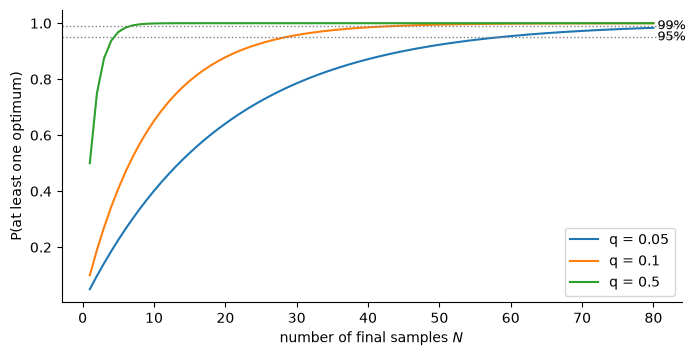

In [ ]:
show_success([0.05, 0.1, 0.5])

**Your turn (textbook exercise 8).**

1. For $q = 0.05$: how many final samples give success with probability at least 95 %?
2. The ring with $p = 1$ has $q \approx 0.5$. How many samples for 99 %?
3. Compare with the number of shots spent *during* the optimisation (in 07 a single-parameter VQE took about 60 000 shots,
   section 1 below): which part of the budget dominates?

In [ ]:
# q, delta = 0.05, 0.05
# print(np.ceil(np.log(delta) / np.log(1 - q)))

<details>
<summary>Solution</summary>

```python
for q, delta in [(0.05, 0.05), (0.5, 0.01)]:
    print(f'q = {q}, success {1 - delta:.0%}: N >= {int(np.ceil(np.log(delta) / np.log(1 - q)))}')
# 59 and 7 samples. The optimisation itself uses tens of thousands of shots (section 1): the final sampling is cheap,
# the hybrid loop is what costs. A fair comparison with classical methods has to count all of it.
```

</details>

## 4. Quantum machine learning

### 4.1 What to expect

Quantum machine learning (QML, textbook chapter 10) asks whether and when a quantum computer helps to learn from data. We take the most
common setting, *classical data, quantum model* (the CQ case). A classical feature vector $\boldsymbol x$ is written into a quantum
state, a circuit with a measurement turns it into a number, and a classical computer trains the model:

$$\boldsymbol x \xrightarrow{\ \text{preprocessing}\ } \tilde{\boldsymbol x} \xrightarrow{\ U_\phi(\tilde{\boldsymbol x})\ } |\phi(\tilde{\boldsymbol x})\rangle
\xrightarrow{\ W(\boldsymbol\theta)\ } \rho_{\boldsymbol x,\boldsymbol\theta} \xrightarrow{\ \text{measure}\ } f_{\boldsymbol\theta}(\boldsymbol x). \qquad (10.1)$$

Three warnings before we start (textbook 10.1):
* **Loading data costs.** There is no usable quantum memory (QRAM) today. Every data point has to be written in by a circuit, and the cost
  of that circuit counts.
* **A large Hilbert space is not enough.** $n$ qubits give a $2^n$-dimensional space, but we only ever learn a few numbers per run.
  Many claimed speedups were later matched by classical algorithms (*dequantisation*).
* **Proven advantages** exist for quantum data, or for specially constructed problems (for example ones built on the discrete
  logarithm). For ordinary classical data nobody has shown an advantage yet.

So the honest aim of this section is to understand how these models work, and how to compare them fairly with classical ones.

### 4.2 Encoding classical data

The **feature map** $\boldsymbol x \mapsto |\phi(\boldsymbol x)\rangle = U_\phi(\boldsymbol x)|0\rangle^{\otimes n}$ is the quantum version of a
classical feature map. It decides what the model can express, how many qubits it needs and how deep the circuit is. First the data are
scaled to a range suitable for angles, for example $\tilde x = \pi(x - x_{\min})/(x_{\max} - x_{\min})$, since rotations by $x$ and $x + 2\pi$
cannot be told apart.

| encoding | state | qubits for $d$ numbers | cost |
|---|---|:-:|---|
| basis | bit string $b_1\dots b_n \mapsto \vert b_1\dots b_n\rangle$ | one per bit | $X$ gates |
| amplitude | $\boldsymbol x \mapsto \frac{1}{\lVert\boldsymbol x\rVert}\sum_j x_j\vert j\rangle$ | $\lceil\log_2 d\rceil$ | a general state preparation, about $d$ gates |
| angle | $\bigotimes_j R_Y(x_j)\vert 0\rangle$, $\ R_Y(x)\vert 0\rangle = \cos\frac x2\vert 0\rangle + \sin\frac x2\vert 1\rangle$ | $d$ | one gate per number |
| phase | $\bigotimes_j P(x_j)\vert +\rangle = \bigotimes_j\frac{\vert 0\rangle + e^{ix_j}\vert 1\rangle}{\sqrt2}$ | $d$ | two gates per number |
| dense | $R_Z(x_2)R_Y(x_1)\vert 0\rangle$: two numbers per qubit (polar and azimuthal angle) | $d/2$ | two gates per pair |

All of them except amplitude encoding give **product states**: every qubit carries its own number. The **ZZ map** (4.5) adds entangling
gates so that pairs of features interact.

Not every choice works. $R_Z(x)|0\rangle = e^{-ix/2}|0\rangle$ is only a global phase, so it encodes nothing.

**Your turn.**
1. Angle encoding: for `xs = [0, np.pi / 3, 2 * np.pi / 3, np.pi]` build $R_Y(x)|0\rangle$ and print the probabilities
   `Statevector(qc).probabilities()`. Which $x$ give a deterministic outcome?
2. Replace `ry` by `rz`. What changes?

SKIP:
3. Amplitude encoding: encode $\boldsymbol x = (4, 8, 5)$ on two qubits (pad with a zero) with
   `qc.append(StatePreparation(v / np.linalg.norm(v)), [0, 1])`. Check the probabilities $(16, 64, 25, 0)/105$ (textbook 10.3.3).
   How many CNOTs does `transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx']).count_ops()` need?

In [ ]:
xs = [0, np.pi / 3, 2 * np.pi / 3, np.pi]

# for x in xs:
#     qc = QuantumCircuit(1)
#     qc.ry(x, 0)
#     print(...)
#
# v = np.array([4, 8, 5, 0])
# qc = QuantumCircuit(2)
# qc.append(StatePreparation(v / np.linalg.norm(v)), [0, 1])
# ...



x = 0.000:  RY -> [1. 0.],  RZ -> [1. 0.]
x = 1.047:  RY -> [0.75 0.25],  RZ -> [1. 0.]
x = 2.094:  RY -> [0.25 0.75],  RZ -> [1. 0.]
x = 3.142:  RY -> [0. 1.],  RZ -> [1. 0.]
[0.152 0.61  0.238 0.   ] [0.152 0.61  0.238 0.   ]
OrderedDict({'rz': 6, 'sx': 4, 'cx': 1})


<details>
<summary>Solution</summary>

```python
xs = [0, np.pi / 3, 2 * np.pi / 3, np.pi]

for x in xs:
    qc_y = QuantumCircuit(1)
    qc_y.ry(x, 0)
    qc_z = QuantumCircuit(1)
    qc_z.rz(x, 0)
    print(f'x = {x:.3f}:  RY -> {Statevector(qc_y).probabilities().round(3)},  RZ -> {Statevector(qc_z).probabilities().round(3)}')
# 1. x = 0 and x = pi give |0> and |1>; in between the outcome is random with P(1) = sin^2(x/2).
# 2. RZ|0> = e^{-ix/2}|0>: always P = (1, 0), the data are lost in a global phase.

v = np.array([4, 8, 5, 0])
qc = QuantumCircuit(2)
qc.append(StatePreparation(v / np.linalg.norm(v)), [0, 1])
print(Statevector(qc).probabilities().round(3), (v**2 / 105).round(3))
print(transpile(qc, basis_gates=['rz', 'sx', 'x', 'cx']).count_ops())
# 3. Two qubits for three numbers, but a general state preparation; the number of gates grows with the length of the vector.
```

</details>

On the Bloch sphere: angle encoding moves the state along a meridian (the xz plane), phase encoding along the equator, and $R_Z$ does not
move $|0\rangle$ at all. Angle encoding can tell $x$ from $2\pi - x$ only up to the sign of $\langle X\rangle$, and phase encoding is periodic
in $2\pi$: the range of the data has to be chosen on purpose.

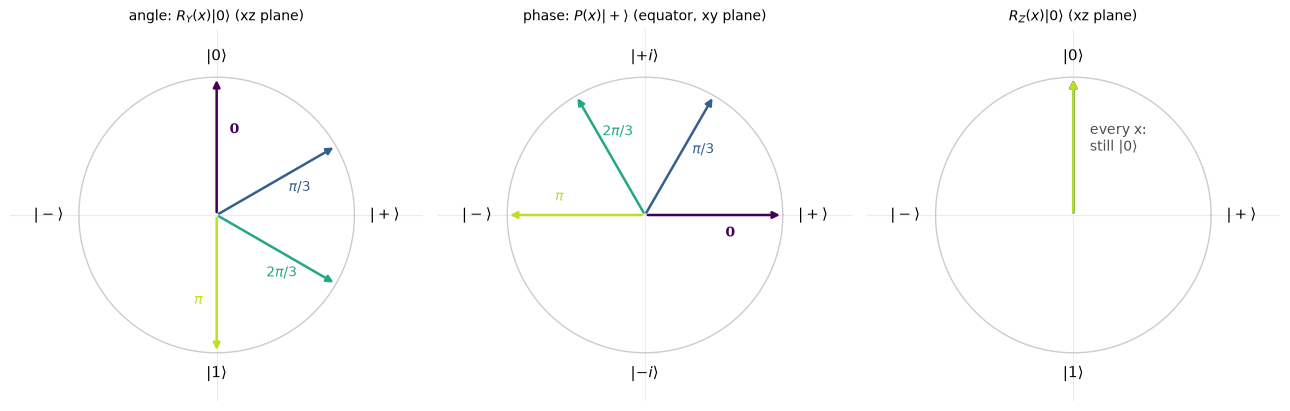

In [ ]:
show_encodings(xs)

### 4.3 A one-qubit variational classifier

**The model.** A variational quantum classifier (VQC) is an encoding $U_\phi(\boldsymbol x)$ followed by a trainable ansatz
$W(\boldsymbol\theta)$ and the expectation value of an observable $O$ (textbook 10.5):

$$f_{\boldsymbol\theta}(\boldsymbol x) = \langle 0|U_\phi^\dagger(\boldsymbol x)\,W^\dagger(\boldsymbol\theta)\,O\,W(\boldsymbol\theta)\,U_\phi(\boldsymbol x)|0\rangle \in [-1, 1].$$

The predicted class is the sign of $f$. Training minimises the **quadratic loss** over the $M$ training points $(x_i, y_i)$ with $y_i = \pm 1$:

$$\mathcal L(\boldsymbol\theta) = \frac1M\sum_{i=1}^M \big(f_{\boldsymbol\theta}(x_i) - y_i\big)^2,$$

with the hybrid loop from section 1. It is VQE with the energy replaced by the loss.

**The smallest example.** $U_\phi(x) = R_Y(x)$, $W(\theta) = R_Y(\theta)$, $O = Z$. Rotations about the same axis add up, so the circuit prepares
$R_Y(x + \theta)|0\rangle$ and

$$f_\theta(x) = \cos(x + \theta). \qquad (10.25)$$

The class boundary is where $x + \theta = \pm\pi/2$: the parameter only shifts the boundary. Textbook example: $x_1 = \pi/3$ in class $+1$,
$x_2 = 4\pi/3$ in class $-1$. Then $\mathcal L(\theta) = (\cos(\pi/3 + \theta) - 1)^2$, with the minimum $\mathcal L = 0$ at
$\theta = -\pi/3 \equiv 5\pi/3$.

**Your turn.**
1. Write `classifier(x, theta)`, returning the circuit $R_Y(x)$ then $R_Y(\theta)$, and `f(x, theta)` that returns
   $\langle Z\rangle$ = `Statevector(qc).expectation_value(Z).real`.
2. Write `loss(theta)` for the two training points, evaluate it on `thetas = np.linspace(0, 2 * np.pi, 121)` and draw it with
   `show_loss(thetas, losses)`. Where is the minimum?
3. Draw the trained model: `show_fits(f, {'trained': theta_best}, X, y)`.

In [ ]:
Z = SparsePauliOp('Z')
X = np.array([np.pi / 3, 4 * np.pi / 3])
y = np.array([1, -1])

# def classifier(x, theta):
#     qc = QuantumCircuit(1)
#     ...
#     return qc
#
# def f(x, theta):
#     return Statevector(classifier(x, theta)).expectation_value(Z).real
#
# def loss(theta):
#     return np.mean([(f(x, theta) - t)**2 for x, t in zip(X, y)])
#
# thetas = np.linspace(0, 2 * np.pi, 121)
# ...

<details>
<summary>Solution</summary>

```python
Z = SparsePauliOp('Z')
X = np.array([np.pi / 3, 4 * np.pi / 3])
y = np.array([1, -1])


def classifier(x, theta):
    qc = QuantumCircuit(1)
    qc.ry(x, 0)          # encoding
    qc.ry(theta, 0)      # trainable layer
    return qc


def f(x, theta):
    return Statevector(classifier(x, theta)).expectation_value(Z).real


def loss(theta):
    return np.mean([(f(x, theta) - t)**2 for x, t in zip(X, y)])


thetas = np.linspace(0, 2 * np.pi, 121)
losses = [loss(theta) for theta in thetas]
show_loss(thetas, losses)
theta_best = thetas[np.argmin(losses)]
print(f'theta = {theta_best:.4f},  5 pi/3 = {5 * np.pi / 3:.4f}')
show_fits(f, {'trained': theta_best}, X, y)
```

</details>

The general version used from now on, with the optimiser instead of a grid. On hardware $f$ would be estimated from shots, and the gradient
from the **parameter-shift rule** $\partial_\theta f = \frac12[f(\theta + \frac\pi2) - f(\theta - \frac\pi2)]$, two extra circuits per
parameter and per training point. Here we use the exact `Statevector` so that only the model is visible.

In [30]:
Z = SparsePauliOp('Z')


def classifier(x, theta):
    qc = QuantumCircuit(1)
    qc.ry(x, 0)
    qc.ry(theta, 0)
    return qc


def f(x, theta):
    return Statevector(classifier(x, theta)).expectation_value(Z).real


def train(model, X, y, n_params: int, starts: int = 3, seed: int = 0):
    # Minimise the quadratic loss from several random starts, return the best parameters
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(starts):
        res = minimize(lambda p: np.mean([(model(x, p) - t)**2 for x, t in zip(X, y)]),
                       rng.uniform(0, 2 * np.pi, n_params), method='COBYLA', options={'maxiter': 300})
        if best is None or res.fun < best.fun:
            best = res
    return best.x


X = np.array([np.pi / 3, 4 * np.pi / 3])
y = np.array([1, -1])
theta_best = train(lambda x, p: f(x, p[0]), X, y, 1)[0]
print(f'COBYLA: theta = {theta_best % (2 * np.pi):.4f}   (5 pi/3 = {5 * np.pi / 3:.4f})')

COBYLA: theta = 5.2360   (5 pi/3 = 5.2360)


**Your turn (textbook exercise 7).** Four points: $x = 0, \pi/2$ in class $+1$ and $x = \pi, 3\pi/2$ in class $-1$.
1. Train the same one-parameter model and draw it. Can it separate the points without error?
2. Is the loss zero at the optimum? Why not? (Write $f$ at the four points with $c = \cos\theta$, $s = \sin\theta$.)

In [ ]:
X4 = np.array([0, np.pi / 2, np.pi, 3 * np.pi / 2])
y4 = np.array([1, 1, -1, -1])

# theta4 = train(lambda x, p: f(x, p[0]), X4, y4, 1)[0]
# show_fits(...)

<details>
<summary>Solution</summary>

```python
X4 = np.array([0, np.pi / 2, np.pi, 3 * np.pi / 2])
y4 = np.array([1, 1, -1, -1])

theta4 = train(lambda x, p: f(x, p[0]), X4, y4, 1)[0]
print(f'theta = {theta4 % (2 * np.pi):.4f}   (7 pi/4 = {7 * np.pi / 4:.4f})')
show_fits(f, {'four points': theta4}, X4, y4)
# f = c, -s, -c, s at the four points; all signs are right for theta in (-pi/2, 0): no classification error.
# Loss = [(1 - c)^2 + (1 + s)^2] / 2, minimal at theta = -pi/4 with L = (1 - 1/sqrt2)^2 = 0.086.
# The points sit at different distances from the boundary, and a cosine cannot be +1 at both 0 and pi/2.
```

</details>

### 4.4 Data re-uploading

**The limitation.** Whatever the trainable layer, a single upload $R_Y(x)$ gives the Bloch vector $(\sin x, 0, \cos x)$, and $f$ is linear
in it: $f(x) = a\cos x + b\sin x$. Only the frequency 1. Data whose classes alternate faster, for example class $+1$ near $0$ and $\pi$ and
class $-1$ near $\pi/2$ and $3\pi/2$, would need $\cos 2x$.

**The fix.** Upload the data several times, alternating with trainable layers (textbook 10.5.3):

$$U(x, \boldsymbol\theta) = W_L(\boldsymbol\theta_L)\,R_Y(x)\cdots W_1(\boldsymbol\theta_1)\,R_Y(x).$$

When a feature enters through a Pauli rotation, the output is a trigonometric polynomial in it, and **the highest frequency equals the number
of uploads $L$**. The trainable layer has to rotate about another axis, here $W = R_Y(b)R_Z(a)$. With $R_Y$ alone everything would
commute and merge into $R_Y(Lx + \theta)$, a single frequency again.

**Your turn.**
1. Write `reupload(x, params)` for $L$ layers, with `params = [a_1, b_1, a_2, b_2, ...]`. In each layer: `ry(x)`, `rz(a)`, `ry(b)`.
2. Train $L = 1, 2, 3$ on the data below with `train(g, X, y, 2 * L)` and draw all three with `show_fits(g, fits, X, y)` (about 20 s).

In [ ]:
rng = np.random.default_rng(3)
X = np.sort(rng.uniform(0, 2 * np.pi, 24))
y = np.sign(np.cos(2 * X)).astype(int)

In [ ]:
# def reupload(x, params):
#     qc = QuantumCircuit(1)
#     for a, b in zip(params[0::2], params[1::2]):
#         ...
#     return qc
#
# def g(x, params):
#     return Statevector(reupload(x, params)).expectation_value(Z).real
#
# fits = {f'L = {L}': train(g, X, y, 2 * L) for L in [1, 2, 3]}
# show_fits(g, fits, X, y)

<details>
<summary>Solution</summary>

```python
def reupload(x, params):
    qc = QuantumCircuit(1)
    for a, b in zip(params[0::2], params[1::2]):
        qc.ry(x, 0)          # upload the data
        qc.rz(a, 0)          # trainable layer W = RY(b) RZ(a)
        qc.ry(b, 0)
    return qc


def g(x, params):
    return Statevector(reupload(x, params)).expectation_value(Z).real


fits = {f'L = {L}': train(g, X, y, 2 * L) for L in [1, 2, 3]}
show_fits(g, fits, X, y)
reupload(0.5, fits['L = 2']).draw('mpl')
```

</details>

With $L = 1$ the best the model can do is a single cosine, so about half of the points end up wrong. With $L = 2$ the model contains $\cos 2x$
and separates the data. $L = 3$ adds a frequency we do not need. More layers mean a richer model, but also more parameters to train and
deeper circuits. Re-uploading also lets one qubit process more features than it has room for: each layer can upload a different feature.

### 4.5 Quantum kernels

**Classical recap: kernels.** A linear classifier predicts $\mathrm{sign}(\boldsymbol w\cdot\boldsymbol x + b)$, and the support vector machine
(SVM) picks the separating line with the largest margin. Data that are not linearly separable can be mapped by a feature map $\Phi$ into a
bigger space where they are. The SVM never needs $\Phi$ itself, only the inner products, the **kernel** $k(\boldsymbol x, \boldsymbol x') = \Phi(\boldsymbol x)\cdot\Phi(\boldsymbol x')$:

$$f(\boldsymbol x) = \sum_{i} \alpha_i y_i\, k(\boldsymbol x_i, \boldsymbol x) + b ,$$

where the coefficients $\alpha_i \ge 0$ come out of a convex optimisation that only needs the **Gram matrix** $K_{ij} = k(\boldsymbol x_i, \boldsymbol x_j)$.
Points with $\alpha_i > 0$ are the *support vectors*. This is the *kernel trick*. Example: the Gaussian (RBF) kernel
$k = e^{-\gamma\lVert\boldsymbol x - \boldsymbol x'\rVert^2}$ corresponds to an infinite-dimensional $\Phi$.

**The quantum kernel** uses the encoded state as the feature vector (textbook 10.4):

$$k(\boldsymbol x, \boldsymbol x') = |\langle\phi(\boldsymbol x)|\phi(\boldsymbol x')\rangle|^2 = \mathrm{Tr}[\rho(\boldsymbol x)\rho(\boldsymbol x')].$$

The square removes the unobservable global phase. A positive semidefinite Gram matrix is guaranteed.

**Measuring it.** Prepare $|0\rangle^{\otimes n}$, apply $U_\phi(\boldsymbol x)$, then $U_\phi^\dagger(\boldsymbol x')$, and measure:

$$P(0^n) = |\langle 0|U_\phi^\dagger(\boldsymbol x')U_\phi(\boldsymbol x)|0\rangle|^2 = k(\boldsymbol x, \boldsymbol x').$$

```
|0>^n ── U(x) ── U†(x') ── measure   ->   k = fraction of 00...0
```

With $N$ shots the estimate has variance $k(1 - k)/N$. Everything else (training the SVM) is classical.

**Example: angle encoding on one qubit.** $\langle\phi(x)|\phi(x')\rangle = \langle 0|R_Y(-x)R_Y(x')|0\rangle = \cos\frac{x' - x}{2}$, so

$$k(x, x') = \cos^2\frac{x - x'}{2} = \frac{1 + \cos x\cos x' + \sin x\sin x'}{2}. \qquad (10.17)$$

**Your turn.**
1. Build the kernel circuit for one qubit: `ry(x)`, then `ry(-xp)`, measure. Estimate $k$ as the fraction of `'0'` for the pairs
   $(0, \pi/2)$, $(0, \pi)$, $(\pi/3, \pi/3)$ and compare with (10.17).
2. On paper (textbook exercise 5): two training points, $x_1 = \pi/4$ in class $+1$ and $x_2 = 3\pi/4$ in class $-1$. Find the Gram matrix
   and the decision function $f(x) = \alpha[k(x_1, x) - k(x_2, x)] + b$ from the conditions $f(x_1) = 1$, $f(x_2) = -1$. Where is the boundary?

In [ ]:
# for x, xp in [(0, np.pi / 2), (0, np.pi), (np.pi / 3, np.pi / 3)]:
#     qc = QuantumCircuit(1)
#     qc.ry(x, 0)
#     qc.ry(-xp, 0)          # U^dagger(x')
#     qc.measure_all()
#     ...

<details>
<summary>Solution</summary>

```python
for x, xp in [(0, np.pi / 2), (0, np.pi), (np.pi / 3, np.pi / 3)]:
    qc = QuantumCircuit(1)
    qc.ry(x, 0)
    qc.ry(-xp, 0)          # U^dagger(x')
    qc.measure_all()
    k = run(qc).get('0', 0) / shots
    print(f'k({x:.3f}, {xp:.3f}) = {k:.3f}   formula {np.cos((x - xp) / 2)**2:.3f}')

# 2. k(pi/4, 3pi/4) = cos^2(pi/4) = 1/2, so K = [[1, 1/2], [1/2, 1]].
#    k(a, x) = (1 + cos(x - a)) / 2, and cos(x - pi/4) - cos(x - 3pi/4) = sqrt2 cos x, so f(x) = alpha cos(x) / sqrt2 + b.
#    f(pi/4) = alpha / 2 + b = 1 and f(3pi/4) = -alpha / 2 + b = -1 give alpha = 2, b = 0: f(x) = sqrt2 cos x,
#    the boundary is x = pi/2, half way between the two points.
```

</details>

**More qubits.** For angle encoding on $n$ qubits the state is a product, and the kernel factorises:

$$k(\boldsymbol x, \boldsymbol x') = \prod_{j=1}^n \cos^2\frac{x_j - x_j'}{2}. \qquad (10.19)$$

A classical computer evaluates this in time $\propto n$, so a product encoding can never give a quantum advantage. The **ZZ feature map**
(textbook 10.3.5) adds entangling phases between pairs of features:

$$|\phi_{ZZ}(\boldsymbol x)\rangle = \prod_{j<k}R_{ZZ}\big(\varphi_{jk}(\boldsymbol x)\big)\bigotimes_j R_Z(x_j)\,\mathsf H^{\otimes n}|0\rangle^{\otimes n},
\qquad \varphi_{jk} = (\pi - x_j)(\pi - x_k).$$

After the Hadamards all gates are diagonal: every bit string has the same probability, and the data sit only in the phases. Repeating the layer
gives a more complicated map. For many qubits and layers such kernels are believed to be hard to compute classically (Havlíček et al., 2019).
For two qubits they are of course still easy.

The general functions from now on: two feature maps, the kernel circuit, and the exact Gram matrix from statevectors, optionally with
simulated shot noise. Each element is then drawn as $\hat k = \text{Binomial}(N, k)/N$, which is what $N$ runs of the kernel circuit would give.

exact: 0.2066781412282152   from shots: 0.225


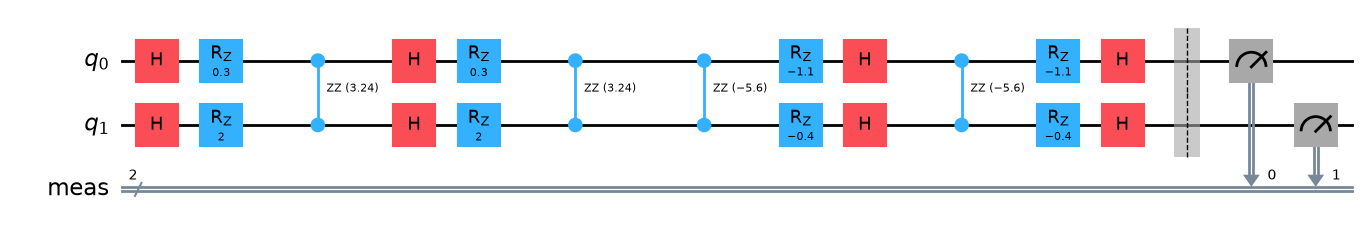

In [ ]:
def angle_map(x) -> QuantumCircuit:
    qc = QuantumCircuit(len(x))
    for j, v in enumerate(x):
        qc.ry(v, j)
    return qc


def zz_map(x, reps: int = 2) -> QuantumCircuit:
    qc = QuantumCircuit(2)
    for _ in range(reps):
        qc.h([0, 1])
        qc.rz(x[0], 0)
        qc.rz(x[1], 1)
        qc.rzz((np.pi - x[0]) * (np.pi - x[1]), 0, 1)
    return qc


def kernel_circuit(fmap, x, xp) -> QuantumCircuit:
    qc = fmap(x).compose(fmap(xp).inverse())
    qc.measure_all()
    return qc


def quantum_kernel(fmap, shots=None):
    # Returns k(A, B): the matrix of |<phi(a)|phi(b)>|^2, exact or with shot noise
    rng = np.random.default_rng(0)
    def k(A, B):
        SA = np.array([Statevector(fmap(a)).data for a in A])
        SB = np.array([Statevector(fmap(b)).data for b in B])
        K = np.abs(SA.conj() @ SB.T)**2
        return K if shots is None else rng.binomial(shots, np.clip(K, 0, 1)) / shots
    return k


x, xp = np.array([0.3, 2.0]), np.array([1.1, 0.4])
print('exact:', quantum_kernel(zz_map)([x], [xp])[0, 0], '  from shots:', run(kernel_circuit(zz_map, x, xp)).get('00', 0) / shots)
kernel_circuit(zz_map, x, xp).draw('mpl', fold=-1)

### 4.6 A kernel SVM on a toy dataset

The dataset is a "checkerboard" in $[0, \pi]^2$: the class is the sign of $\cos x_1 \cos x_2$, so opposite quadrants share a class (the XOR
problem). No straight line can separate it.

The SVM itself is classical: maximise $\sum_i\alpha_i - \frac12\sum_{ij}\alpha_i\alpha_j y_i y_j K_{ij}$ with $0 \le \alpha_i \le C$ and
$\sum_i \alpha_i y_i = 0$. We solve it with SciPy in a few lines. The same thing as `sklearn.svm.SVC(kernel='precomputed')`.

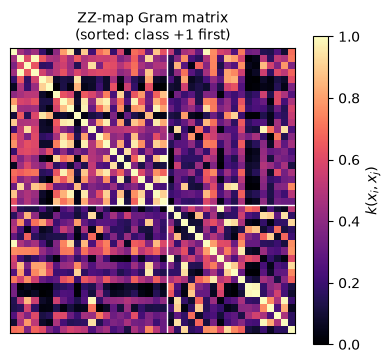

In [ ]:
def svm_fit(K, y, C: float = 10.0):
    # Dual SVM: returns alpha and the offset b
    Q = (y[:, None] * y[None, :]) * K
    res = minimize(lambda a: 0.5 * a @ Q @ a - a.sum(), np.zeros(len(y)), jac=lambda a: Q @ a - 1,
                   bounds=[(0, C)] * len(y), constraints=[{'type': 'eq', 'fun': lambda a: a @ y, 'jac': lambda a: y}],
                   method='SLSQP')
    alpha = res.x
    margin = (alpha > 1e-6) & (alpha < C - 1e-6)            # support vectors exactly on the margin
    b = np.mean(y[margin] - (alpha * y) @ K[:, margin]) if margin.any() else 0.0
    return alpha, b


def svm_predict(K_train_new, y, alpha, b):
    # K_train_new[i, m] = k(x_i, new point m)
    return K_train_new.T @ (alpha * y) + b


def checkerboard(m: int, seed: int):
    rng = np.random.default_rng(seed)
    X = rng.uniform(0, np.pi, (m, 2))
    return X, np.sign(np.cos(X[:, 0]) * np.cos(X[:, 1]))


X_train, y_train = checkerboard(40, seed=1)
X_test, y_test = checkerboard(200, seed=2)

kernels = {
    'linear (classical)': lambda A, B: A @ B.T,
    'RBF (classical)': lambda A, B: np.exp(-((A[:, None, :] - B[None, :, :])**2).sum(-1)),
    'angle map (quantum)': quantum_kernel(angle_map),
    'ZZ map (quantum)': quantum_kernel(zz_map),
}
show_gram(kernels['ZZ map (quantum)'](X_train, X_train), y_train, 'ZZ-map Gram matrix')

Bright blocks on the diagonal mean that points of the same class look similar to the kernel. Now train all four and draw the decision
regions. Circles mark the support vectors.

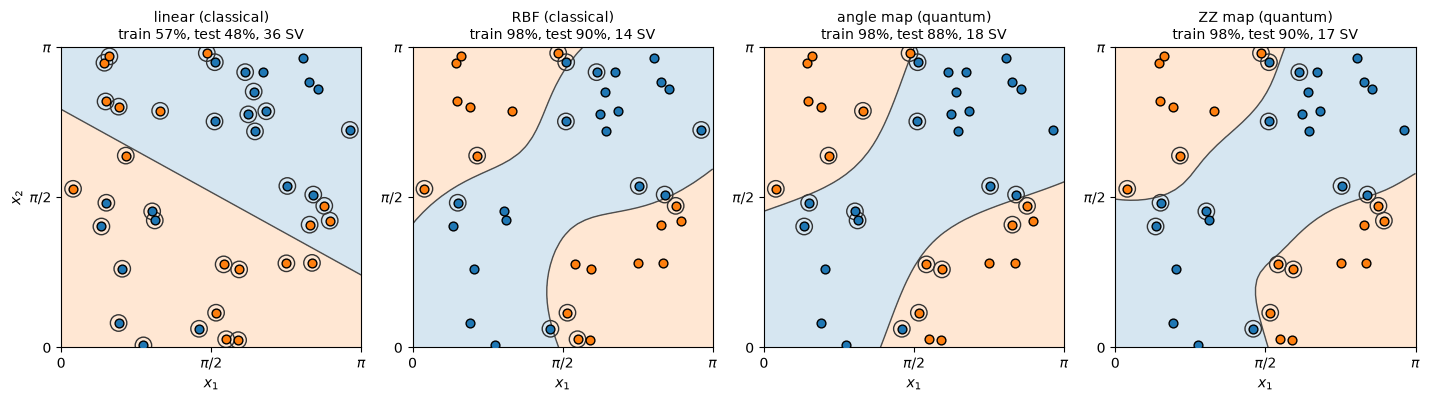

In [ ]:
show_svm(kernels, X_train, y_train, X_test, y_test)

The linear kernel stays near chance level. The two quantum kernels do about as well as the classical RBF kernel. The angle-map result has a
simple explanation: by (10.19) its feature space contains $\cos x_1\cos x_2$, exactly the function that defines the classes. It is a good kernel
for this problem, and a classical computer evaluates it in microseconds. **Higher accuracy on a small dataset is no proof of a quantum
advantage** (textbook 10.5.5): compare against a well-tuned classical model, and count circuits, shots and time.

**Your turn.**
1. How many kernel circuits does training need for $M = 40$ points? And how many to predict the 200 test points (only the support vectors
   count)?
2. Replace the exact quantum kernels by estimates with `shots=50` and `shots=500`, for example
   `kernels['ZZ map, 50 shots'] = quantum_kernel(zz_map, shots=50)`, and run `show_svm` again. What happens to the accuracy?

In [ ]:
# print(...)
# noisy = {'ZZ map, exact': quantum_kernel(zz_map), ...}
# show_svm(noisy, X_train, y_train, X_test, y_test)

<details>
<summary>Solution</summary>

```python
M = len(X_train)
alpha, b = svm_fit(kernels['ZZ map (quantum)'](X_train, X_train), y_train)
n_sv = int((alpha > 1e-6).sum())
print(f'training: M(M-1)/2 = {M * (M - 1) // 2} circuits (the diagonal is 1),  prediction: {n_sv} x {len(X_test)} = {n_sv * len(X_test)}')
# each circuit with N shots: 780 x 1000 = 780 000 shots just for the training Gram matrix

noisy = {'ZZ map, exact': quantum_kernel(zz_map),
         'ZZ map, 500 shots': quantum_kernel(zz_map, shots=500),
         'ZZ map, 50 shots': quantum_kernel(zz_map, shots=50)}
show_svm(noisy, X_train, y_train, X_test, y_test)
# With 50 shots the kernel values have errors of about 0.07, the decision boundary gets ragged and the test accuracy drops.
# The training itself is a convex problem; all the difficulty sits in estimating the kernel precisely.
```

</details>

### 4.7 Kernel concentration

There is a catch, the kernel analogue of barren plateaus (textbook 10.4.5). Take the product kernel (10.19) with features drawn uniformly
from $[0, \pi]$. One factor has the mean

$$\mathbb E\Big[\cos^2\frac{x_j - x_j'}{2}\Big] = \frac12 + \frac12\mathbb E[\cos x_j]\,\mathbb E[\cos x_j'] + \frac12\mathbb E[\sin x_j]\,\mathbb E[\sin x_j']
= \frac12 + \frac{2}{\pi^2} \approx 0.70 ,$$

and the factors are independent, so $\mathbb E[k] \approx 0.70^n$. For $n = 20$ that is about $10^{-3}$. The off-diagonal elements of the Gram
matrix become exponentially small, the matrix approaches the identity, and every point looks equally unrelated to every other.

Worse, once $k < 1/N$, $N$ shots usually contain no $0^n$ at all and the estimate is exactly 0. The model then cannot tell inputs apart.
Thanasilp et al. (2024) showed this is general: very expressive encodings, global measurements, strong entanglement and noise all
concentrate the kernel. A rich encoding is needed for any advantage, and too rich an encoding makes the kernel impossible to estimate.

**Your turn (on paper).** Check $\mathbb E[\cos x] = 0$ and $\mathbb E[\sin x] = 2/\pi$ for $x$ uniform on $[0, \pi]$. For which $n$ does
$0.70^n$ drop below $1/N$ with $N = 1000$ shots? Then run the cell below. It uses formula (10.19), which is itself the point: a classical
computer evaluates this kernel without any quantum circuit.

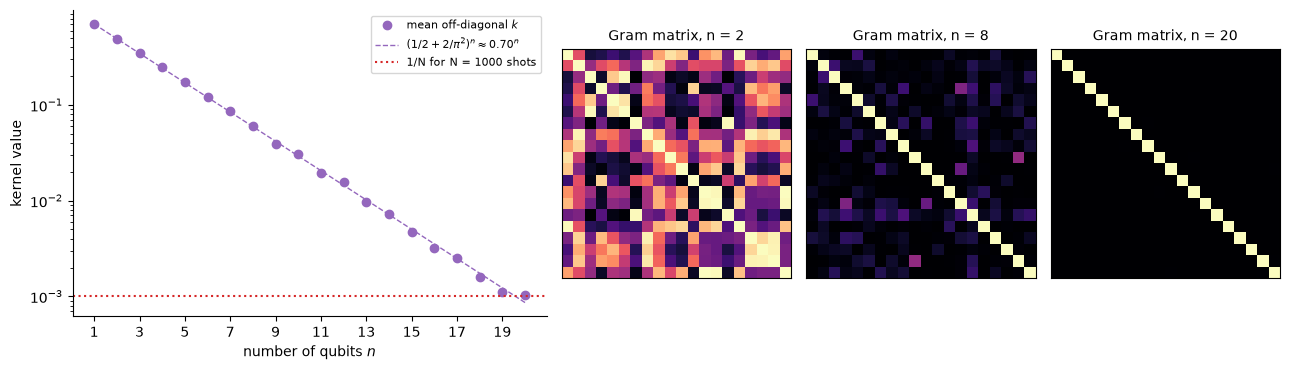

In [ ]:
rng = np.random.default_rng(5)
ns = list(range(1, 21))
mean_k = []
for n in ns:
    A, B = rng.uniform(0, np.pi, (2, 2000, n))
    mean_k.append(np.mean(np.prod(np.cos((A - B) / 2)**2, axis=1)))


def product_gram(n: int, m: int = 20):
    P = rng.uniform(0, np.pi, (m, n))
    return np.prod(np.cos((P[:, None, :] - P[None, :, :]) / 2)**2, axis=2)


show_concentration(ns, mean_k, shots, {n: product_gram(n) for n in [2, 8, 20]})

<details>
<summary>Solution</summary>

$\mathbb E[\cos x] = \frac1\pi\int_0^\pi\cos x\,dx = 0$ and $\mathbb E[\sin x] = \frac1\pi\int_0^\pi\sin x\,dx = \frac2\pi$, so the mean of one factor is
$\frac12 + \frac12\cdot\frac4{\pi^2} = \frac12 + \frac2{\pi^2}$. $0.70^n < 10^{-3}$ for $n > \ln(10^{-3})/\ln 0.70 \approx 19.4$, so from $n = 20$
qubits a typical kernel value is no longer resolved by 1000 shots, and the Gram matrix on the right is practically the identity.

</details>

## Summary

* A variational algorithm = a short parametrised circuit + measurements + a classical optimiser. The cost is estimated from many shots.
* QUBO $\to$ Ising via $x_i = (1 - z_i)/2$. Constraints go in as penalties with a large enough $P$.
* QAOA: the cost layer writes the quality of each bit string into its phase, the mixer turns phases into probabilities. Its result is a
  sampled bit string. Report the mean, the best sample and $P(\text{optimum})$, and compare with a random guess.
* QML (CQ case): **encoding** $\to$ trainable circuit or kernel $\to$ measurement $\to$ classical training. The encoding decides what the model
  can express. $R_Z|0\rangle$ encodes nothing, and amplitude encoding saves qubits but not gates.
* A one-upload classifier only contains $\cos x$ and $\sin x$. **Re-uploading** $L$ times gives frequencies up to $L$.
* A **quantum kernel** $|\langle\phi(x)|\phi(x')\rangle|^2$ is measured as $P(0^n)$ of $U(x)U^\dagger(x')$, and the SVM is trained classically.
  Product encodings give classically computable kernels.
* **Kernel concentration**: for expressive encodings on many qubits the kernel values shrink exponentially and cannot be estimated with a
  polynomial number of shots.
* A fair comparison always includes a good classical model and the full cost in circuits and shots.